# 260901B2: omega dependence of the XRD pattern and origin of the 23 deg peak

Seven grazing-incidence 2-theta scans (omega = 0.1 to 1.1 deg, 20 to 35 deg 2-theta, identical counting time) of sample 260901B2, loaded from the NOMAD archives staged by notebook 1.

How omega is used to separate origins:
- **Film (BaCuSe layer) reflections**: intensity rises from 0.1 deg to about the critical angle, then stays roughly flat or grows slowly as the beam penetrates the whole film.
- **Surface species (oxide/selenate, top-layer Cu2Se)**: strongest at the lowest omega and fading in relative terms as the beam goes deeper.
- **Substrate (SLG amorphous hump, broad ~20-30 deg)**: grows monotonically with omega as the beam reaches the glass, and is much broader (FWHM of several degrees) than a crystalline reflection.
- **Peak position vs omega**: a film reflection stays fixed in 2-theta in this geometry; shifts point to refraction/height errors rather than a new phase.

Intensities are raw counts per step; all scans use the same step (0.02 deg) and time per step, so absolute counts are comparable.

In [1]:
import sys
import json
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

from xrd_bo_optimization_tf.config import FIGURES_DIR, MATCH_TOL, NOMAD_STAGING_DIR, RESULTS_DATA_DIR
from xrd_bo_optimization_tf.peak_analysis import analyze_scan
from xrd_bo_optimization_tf.phase_matching import load_reference_cards

SAMPLE = '260901B2'
UPLOAD = NOMAD_STAGING_DIR / 'TBRSU9POTmKRrd1aytChkA'
FOCUS_2THETA = 23.0
OUT_PREFIX = FIGURES_DIR / f'{SAMPLE}_omega'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
references = load_reference_cards()


def read_result(path):
    data = json.loads(path.read_text(encoding='utf-8'))['data']
    result = data['results'][0]
    return {
        'name': data['name'],
        'omega': float(result['omega'][0]),
        'two_theta': np.asarray(result['two_theta'], dtype=float),
        'intensity': np.asarray(result['intensity'], dtype=float),
    }


# 'BCS I*' matches the result entries; the '.xrdml data file' entries use 'BCS_I'.
scans = sorted(
    (read_result(p) for p in UPLOAD.glob(f'{SAMPLE} BCS I* GI*.archive.json')),
    key=lambda s: s['omega'],
)
omegas = np.array([s['omega'] for s in scans])
two_theta = scans[0]['two_theta']
assert all(np.allclose(s['two_theta'], two_theta) for s in scans)
counts = np.vstack([s['intensity'] for s in scans])
print(pd.DataFrame({
    'entry': [s['name'] for s in scans],
    'omega_deg': omegas,
    'max_counts': counts.max(axis=1),
    'median_counts': np.median(counts, axis=1),
}).to_string(index=False))

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



AttributeError: _ARRAY_API not found

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



                entry  omega_deg  max_counts  median_counts
 260901B2 BCS I2 GI01        0.1       179.0           42.5
 260901B2 BCS I4 GI02        0.2       279.0           54.0
 260901B2 BCS I6 GI03        0.3       189.0           66.0
 260901B2 BCS I8 GI05        0.5       281.0           50.0
260901B2 BCS I10 GI07        0.7       359.0           42.0
260901B2 BCS I12 GI09        0.9       446.0           38.0
260901B2 BCS I14 GI11        1.1       106.0           36.0


## 1. Stacked patterns with reference reflections

Vertical marks are ICDD reflections (>= 10 % intensity) of each phase. Look at which phases have a line within the matching tolerance of the 23 deg peak.

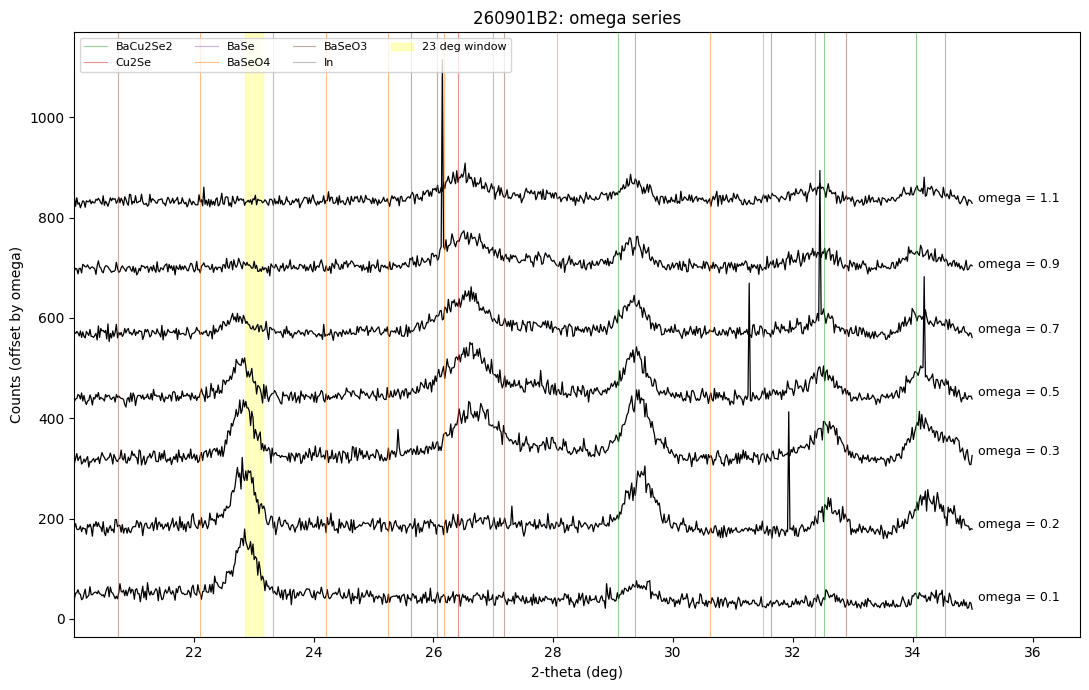

Reference reflections within 0.4 deg of 23.0 deg:
  BaSe: [23.326]


In [2]:
phase_colors = {'BaCu2Se2': 'tab:green', 'Cu2Se': 'tab:red', 'BaSe': 'tab:purple',
                'BaSeO4': 'tab:orange', 'BaSeO3': 'tab:brown', 'Au': 'goldenrod', 'In': 'gray'}
lo, hi = two_theta.min(), two_theta.max()

fig, ax = plt.subplots(figsize=(11, 7))
offset = 0.6 * counts.max() / 2
for i, (omega, row) in enumerate(zip(omegas, counts)):
    ax.plot(two_theta, row + i * offset, lw=0.9, color='k')
    ax.text(hi + 0.1, i * offset + np.median(row), f'omega = {omega:.1f}', va='center', fontsize=9)
top = counts.max() + (len(omegas) - 1) * offset
for phase, positions in references.items():
    for j, pos in enumerate(p for p in positions if lo <= p <= hi):
        ax.axvline(pos, color=phase_colors.get(phase, 'gray'), lw=0.8, alpha=0.5,
                   label=phase if j == 0 else None)
ax.axvspan(FOCUS_2THETA - MATCH_TOL, FOCUS_2THETA + MATCH_TOL, color='yellow', alpha=0.25, label='23 deg window')
ax.set_xlim(lo, hi + 1.8)
ax.set_xlabel('2-theta (deg)')
ax.set_ylabel('Counts (offset by omega)')
ax.set_title(f'{SAMPLE}: omega series')
ax.legend(ncol=4, fontsize=8, loc='upper left')
fig.tight_layout()
fig.savefig(f'{OUT_PREFIX}_stacked_patterns.png', dpi=200)
plt.show()

print(f'Reference reflections within 0.4 deg of {FOCUS_2THETA} deg:')
for phase, positions in references.items():
    near = [round(p, 3) for p in positions if abs(p - FOCUS_2THETA) <= 0.4]
    if near:
        print(f'  {phase}: {near}')

## 2. Intensity map (omega vs 2-theta)

A film reflection appears as a vertical stripe with intensity that builds up above the critical angle; a substrate hump is a broad, slowly varying background that grows with omega.

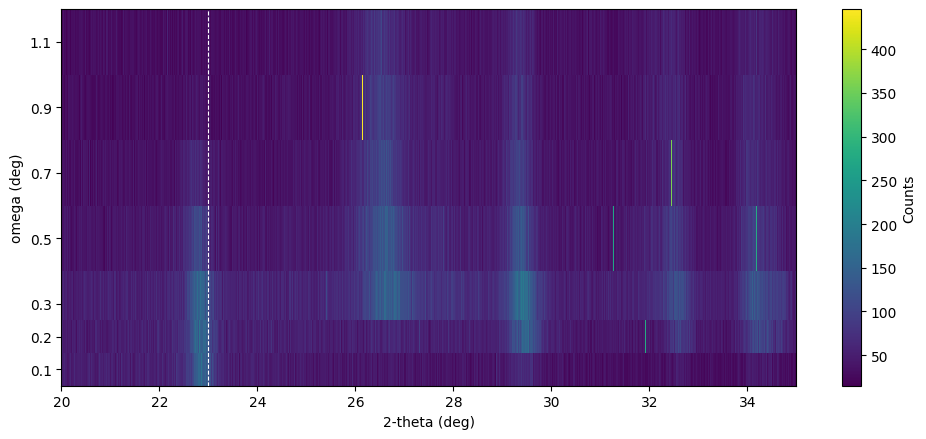

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5))
mesh = ax.pcolormesh(two_theta, omegas, counts, shading='nearest', cmap='viridis')
ax.set_yticks(omegas)
ax.axvline(FOCUS_2THETA, color='w', ls='--', lw=0.8)
ax.set_xlabel('2-theta (deg)')
ax.set_ylabel('omega (deg)')
fig.colorbar(mesh, label='Counts')
fig.tight_layout()
fig.savefig(f'{OUT_PREFIX}_intensity_map.png', dpi=200)
plt.show()

## 3. Peak list from the omega-summed pattern

Peaks are detected on the sum of all omegas (best signal) with the project's standard preprocessing, then matched to reference cards within the project tolerance. The 23 deg peak is always tracked, even if it falls below the detection threshold.

In [4]:
summed = counts.sum(axis=0)
summed_result = analyze_scan(two_theta, summed)
peak_positions = list(two_theta[summed_result['detected_peaks']])

window = (two_theta > FOCUS_2THETA - 0.5) & (two_theta < FOCUS_2THETA + 0.5)
focus_center = float(two_theta[window][np.argmax(summed_result['smooth'][window])])
if not any(abs(p - focus_center) < 0.15 for p in peak_positions):
    peak_positions.append(focus_center)
peak_positions = sorted(peak_positions)


def match_phases(position, tolerance=MATCH_TOL):
    hits = []
    for phase, reflections in references.items():
        delta = min(((p - position) for p in reflections), key=abs)
        if abs(delta) <= tolerance:
            hits.append(f'{phase} ({delta:+.2f})')
    return ', '.join(hits) if hits else 'unmatched'


peak_table = pd.DataFrame({
    'two_theta': np.round(peak_positions, 3),
    'matches (delta to card)': [match_phases(p) for p in peak_positions],
})
peak_table['focus'] = np.isclose(peak_table['two_theta'], focus_center, atol=0.01)
peak_table

,two_theta,matches (delta to card),focus
0,22.81,unmatched,True
1,26.59,unmatched,False
2,29.41,BaCu2Se2 (-0.04),False
3,32.53,BaCu2Se2 (-0.02),False
4,34.15,BaCu2Se2 (-0.09),False


## 4. Peak fits per omega

Each tracked peak is fitted with a Gaussian plus linear background in a +/-0.35 deg window, weighted by counting (Poisson) errors. Reported: net area, centre, FWHM, and their uncertainties.

In [5]:
def gauss_linear(x, amp, center, sigma, b0, b1, x0):
    return amp * np.exp(-0.5 * ((x - center) / sigma) ** 2) + b0 + b1 * (x - x0)


def fit_peak(x_all, y_all, center, half_width=0.35):
    mask = (x_all >= center - half_width) & (x_all <= center + half_width)
    x, y = x_all[mask], y_all[mask]
    model = lambda xx, a, c, s, b0, b1: gauss_linear(xx, a, c, s, b0, b1, center)
    p0 = [max(y.max() - np.median(y), 1.0), center, 0.08, float(np.median(y)), 0.0]
    lower = [0, center - 0.2, 0.02, -np.inf, -np.inf]
    upper = [np.inf, center + 0.2, 0.5, np.inf, np.inf]
    try:
        popt, pcov = curve_fit(model, x, y, p0=p0, bounds=(lower, upper),
                               sigma=np.sqrt(np.clip(y, 1, None)), absolute_sigma=True)
    except (RuntimeError, ValueError):
        return dict.fromkeys(['area', 'area_err', 'center', 'center_err', 'fwhm', 'fwhm_err', 'height'], np.nan)
    amp, cen, sig = popt[:3]
    area_var = 2 * np.pi * (sig ** 2 * pcov[0, 0] + amp ** 2 * pcov[2, 2] + 2 * amp * sig * pcov[0, 2])
    area_err = float(np.sqrt(max(area_var, 0.0)))
    return {
        'area': amp * sig * np.sqrt(2 * np.pi),
        'area_err': area_err,
        'center': cen,
        'center_err': float(np.sqrt(pcov[1, 1])),
        'fwhm': 2.3548 * sig,
        'fwhm_err': 2.3548 * float(np.sqrt(pcov[2, 2])),
        'height': amp,
    }


records = []
for omega, row in zip(omegas, counts):
    clean = analyze_scan(two_theta, row)['cleaned']
    for position in peak_positions:
        fit = fit_peak(two_theta, clean, position)
        records.append({'omega': omega, 'peak': round(position, 2), **fit})
fits = pd.DataFrame(records)
fits['significant'] = fits['area'] > 3 * fits['area_err']  # area > 3 sigma
fits.to_csv(RESULTS_DATA_DIR / f'{SAMPLE}_omega_peak_fits.csv', index=False)
fits.pivot(index='peak', columns='omega', values='area').round(1)

omega,0.1,0.2,0.3,0.5,0.7,0.9,1.1
peak,,,,,,,
22.81,41.1,45.7,52.1,41.3,8.5,72.5,0.5
26.59,0.9,NaN,166.3,33.7,8.0,140.6,3.2
29.41,80.3,72.2,53.8,26.3,21.3,143.7,171.1
32.53,9.5,10.9,42.9,16.2,10.2,109.6,22.1
34.15,1.9,15.6,26.3,11.3,5.5,10.3,18.0


## 5. Intensity vs omega for each peak

Left: net area. Right: area normalised to its maximum, which makes the shape of the omega dependence comparable between peaks. The 23 deg peak is the thick black line.

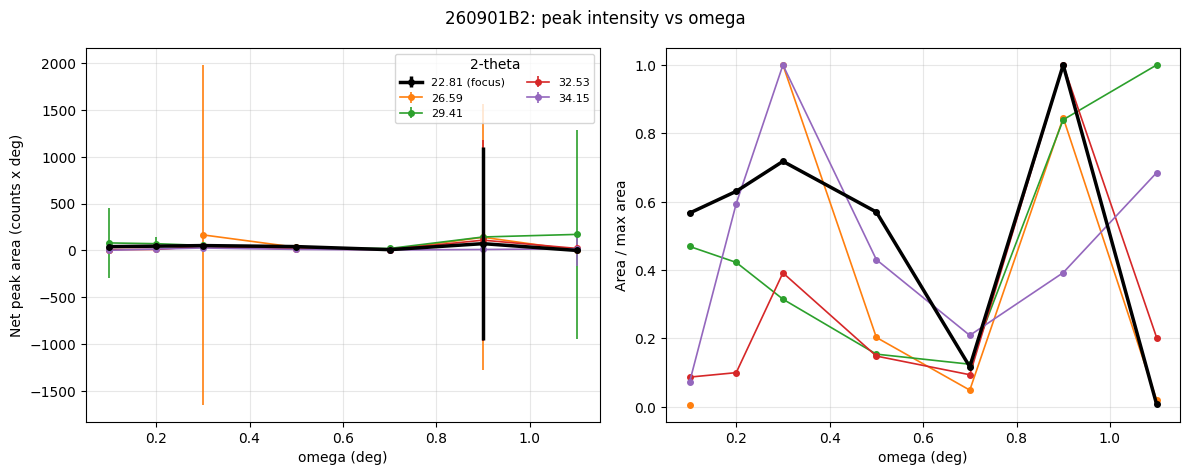

In [6]:
focus_label = round(focus_center, 2)
cmap = plt.get_cmap('tab10')
fig, (ax_abs, ax_norm) = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
for k, (peak, group) in enumerate(fits.groupby('peak')):
    group = group.sort_values('omega')
    is_focus = peak == focus_label
    style = dict(color='k', lw=2.5, zorder=5) if is_focus else dict(color=cmap(k % 10), lw=1.2)
    label = f'{peak:.2f}' + (' (focus)' if is_focus else '')
    ax_abs.errorbar(group['omega'], group['area'], yerr=group['area_err'], marker='o', ms=4, label=label, **style)
    top = group['area'].max()
    if np.isfinite(top) and top > 0:
        ax_norm.plot(group['omega'], group['area'] / top, marker='o', ms=4, **style)
ax_abs.set_ylabel('Net peak area (counts x deg)')
ax_norm.set_ylabel('Area / max area')
for ax in (ax_abs, ax_norm):
    ax.set_xlabel('omega (deg)')
    ax.grid(alpha=0.3)
ax_abs.legend(title='2-theta', fontsize=8, ncol=2)
fig.suptitle(f'{SAMPLE}: peak intensity vs omega')
fig.tight_layout()
fig.savefig(f'{OUT_PREFIX}_peak_intensity_vs_omega.png', dpi=200)
plt.show()

## 6. Position and width of the 23 deg peak vs omega, and substrate hump check

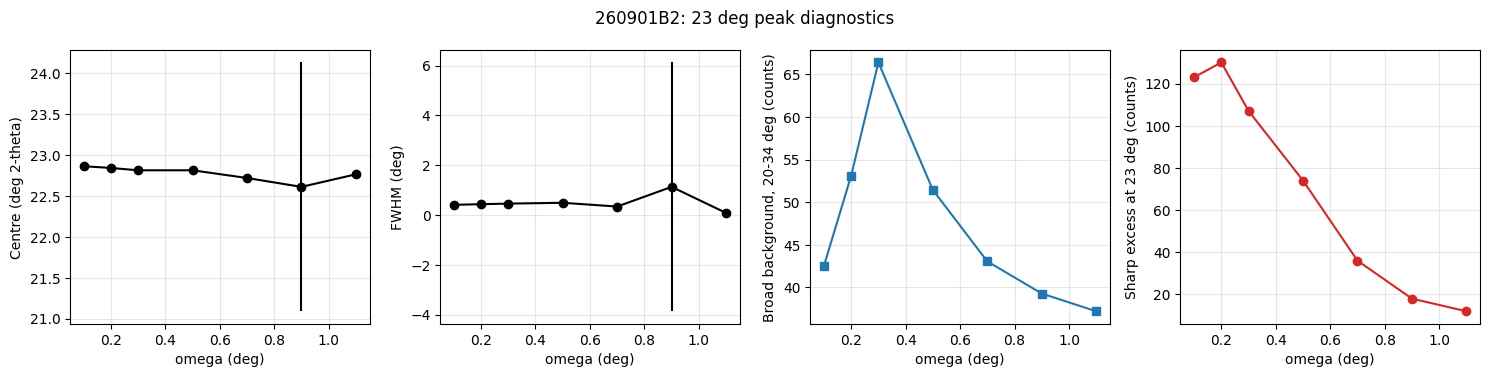

,omega,peak,area,area_err,center,center_err,fwhm,fwhm_err,height,significant
0,0.1,22.81,41.091,12.117,22.862,0.017,0.406,0.064,94.983,True
5,0.2,22.81,45.721,14.375,22.841,0.017,0.432,0.071,99.431,True
10,0.3,22.81,52.086,16.560,22.812,0.016,0.455,0.076,107.628,True
15,0.5,22.81,41.321,17.965,22.813,0.021,0.488,0.107,79.477,False
20,0.7,22.81,8.461,6.036,22.718,0.040,0.337,0.129,23.597,False
25,0.9,22.81,72.547,1028.159,22.610,1.521,1.128,4.999,60.423,False
30,1.1,22.81,0.482,0.401,22.763,0.029,0.080,0.069,5.628,False


In [7]:
focus = fits[fits['peak'] == focus_label].sort_values('omega')

# Broad low-frequency component: heavy median smoothing approximates a glass hump.
from scipy.ndimage import median_filter
hump_window = (two_theta >= 20) & (two_theta <= 34)
hump = np.array([
    median_filter(row, size=151, mode='nearest')[hump_window].mean() for row in counts
])
sharp = np.array([
    (row - median_filter(row, size=151, mode='nearest'))[(two_theta > FOCUS_2THETA - 0.3) & (two_theta < FOCUS_2THETA + 0.3)].max()
    for row in counts
])

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
axes[0].errorbar(focus['omega'], focus['center'], yerr=focus['center_err'], marker='o', color='k')
axes[0].set_ylabel('Centre (deg 2-theta)')
axes[1].errorbar(focus['omega'], focus['fwhm'], yerr=focus['fwhm_err'], marker='o', color='k')
axes[1].set_ylabel('FWHM (deg)')
axes[2].plot(omegas, hump, marker='s', color='tab:blue')
axes[2].set_ylabel('Broad background, 20-34 deg (counts)')
axes[3].plot(omegas, sharp, marker='o', color='tab:red')
axes[3].set_ylabel('Sharp excess at 23 deg (counts)')
for ax in axes:
    ax.set_xlabel('omega (deg)')
    ax.grid(alpha=0.3)
fig.suptitle(f'{SAMPLE}: 23 deg peak diagnostics')
fig.tight_layout()
fig.savefig(f'{OUT_PREFIX}_focus_peak_diagnostics.png', dpi=200)
plt.show()
focus.round(3)

## 7. Ratios to the BaCu2Se2 reflections

If the 23 deg peak belongs to the BaCuSe layer, its ratio to the film reflections should be roughly constant with omega. A rising or falling ratio points to a species at a different depth.

BaCu2Se2-matched peaks used as denominator: [np.float64(29.41), np.float64(32.53), np.float64(34.15)]


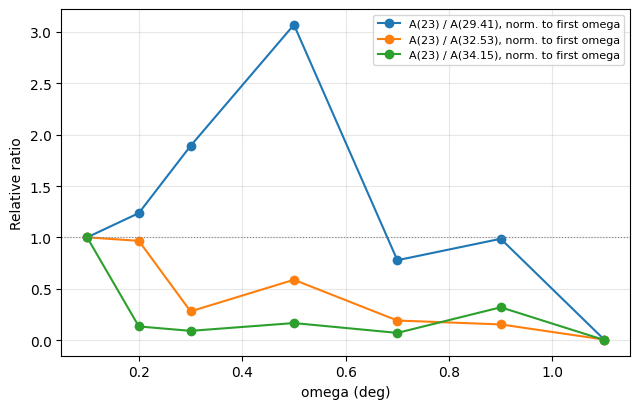

In [8]:
target_peaks = [round(p, 2) for p in peak_positions
                if 'BaCu2Se2' in match_phases(p) and round(p, 2) != focus_label]
print('BaCu2Se2-matched peaks used as denominator:', target_peaks)

pivot = fits.pivot(index='omega', columns='peak', values='area')
if target_peaks:
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    for peak in target_peaks:
        ratio = pivot[focus_label] / pivot[peak]
        ax.plot(pivot.index, ratio / ratio.dropna().iloc[0], marker='o', label=f'A(23) / A({peak:.2f}), norm. to first omega')
    ax.axhline(1, color='gray', lw=0.8, ls=':')
    ax.set_xlabel('omega (deg)')
    ax.set_ylabel('Relative ratio')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(f'{OUT_PREFIX}_focus_ratio_to_film_peaks.png', dpi=200)
    plt.show()

## 8. Is the 23 deg feature present in the other 260901 samples (GI 0.2 deg)?

The same feature in every sample, regardless of composition, would indicate the substrate or the instrument. A feature that follows the BaCuSe content points to the layer or a related phase. The new SLG scans (260901A1, A2, A4) are included.

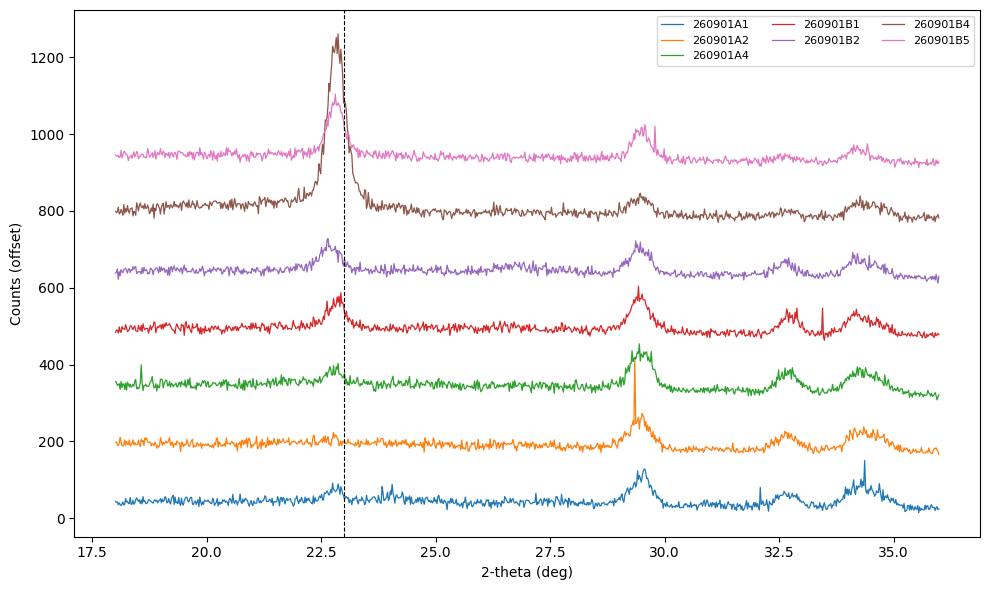

,sample,excess_at_23_over_20-22.5_median,peak_position
0,260901A1,47.0,22.8
1,260901A2,28.0,22.8
2,260901A4,52.0,22.9
3,260901B1,89.0,22.9
4,260901B2,61.0,22.8
5,260901B4,437.0,22.9
6,260901B5,155.0,22.8


In [9]:
def load_gi02(name_glob):
    out = {}
    for path in sorted(UPLOAD.glob(name_glob)):
        if 'xrdml' in path.name or 'processing' in path.name:
            continue
        data = json.loads(path.read_text(encoding='utf-8'))['data']
        if not data.get('results'):
            continue
        result = data['results'][0]
        if abs(result['omega'][0] - 0.2) > 1e-6 or len(result['two_theta']) < 2000:
            continue
        out[data['name'].split()[0]] = (np.asarray(result['two_theta']), np.asarray(result['intensity']))
    return out


gi02 = {**load_gi02('260901A* GI02.archive.json'), **load_gi02('260901B* GI02.archive.json')}
fig, ax = plt.subplots(figsize=(10, 6))
rows = []
for i, (sample, (tt, yy)) in enumerate(sorted(gi02.items())):
    sel = (tt >= 18) & (tt <= 36)
    ax.plot(tt[sel], yy[sel] + i * 150, lw=0.9, label=sample)
    near = (tt > FOCUS_2THETA - 0.3) & (tt < FOCUS_2THETA + 0.3)
    base = np.median(yy[(tt > 20) & (tt < 22.5)])
    rows.append({'sample': sample, 'excess_at_23_over_20-22.5_median': float(yy[near].max() - base),
                 'peak_position': float(tt[near][np.argmax(yy[near])])})
ax.axvline(FOCUS_2THETA, color='k', ls='--', lw=0.8)
ax.set_xlabel('2-theta (deg)')
ax.set_ylabel('Counts (offset)')
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(f'{OUT_PREFIX}_other_samples_gi02.png', dpi=200)
plt.show()
pd.DataFrame(rows).round(1)

## 9. Reading the results

Fill in after running, using the figures above:

| Observation | Film (BaCuSe) | Surface impurity | Substrate / glass |
|---|---|---|---|
| Area vs omega | rises, plateaus above the critical angle | max at lowest omega, then falls relative to film peaks | grows steadily with omega |
| Ratio to BaCu2Se2 peaks | constant | decreasing with omega | increasing with omega |
| FWHM | similar to film peaks | similar or broader | several degrees (hump) |
| Present in other samples | scales with BaCuSe content | scales with oxidation/selenisation | same in all samples |
| Matches an ICDD line within 0.15 deg | BaCu2Se2 | Cu2Se, BaSe, BaSeO3/4 | none |